In [10]:
import numpy as np
import xarray as xr
import h5py
import scipy.linalg as spl
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1 import make_axes_locatable
import tensorflow as tf
import matplotlib
import os
font = {'family' : 'serif',
        'weight' : 'normal',
        'size'   : 22}

In [11]:
rl2e_y = lambda yest, yref : spl.norm(yest - yref, 2) / spl.norm(yref, 2)

def eigenpairs(x):
    meanx = np.mean(x,axis=1)
    cov = np.cov(x)
    lam,Phi = np.linalg.eigh(cov+np.sqrt(np.finfo(float).eps) * np.eye(cov.shape[0]))
    idx = lam.argsort()[::-1]
    lamx = lam[idx]
    Phix = Phi[:,idx]
    Psix = Phix @ np.diag(np.sqrt(lamx))
    return meanx, lamx, Psix

def mesh_recon_y(arr):
    mesh = np.zeros(800)
    mesh[np.where(~np.isnan(y_ens_mesh[0,:,:,0].flatten()))] = arr
    mesh[np.where(np.isnan(y_ens_mesh[0,:,:,0].flatten()))] = np.nan
    mesh = mesh.reshape((40,20))
    return mesh

def mesh_recon_h(arr):
    recon_size = arr.shape[0]
    mesh = np.zeros(40*20*25)
    for i in range(recon_size):
        mesh[np.where(~np.isnan(h_raw[:,:,:,0].flatten()))[0]] = arr
        mesh[np.where(np.isnan(h_raw[:,:,:,0].flatten()))[0]] = np.nan
    mesh = mesh.reshape((25,40,20))
    return mesh

In [12]:
y_ens_mesh = np.log(xr.open_dataset('data/freyberg_tv_3d_k_k33_head_realizations.nc')['k'].values[:])

# h_raw = ds['head'].values[:,0,:,:,:]
# y_raw = np.log(ds['k'].values[0,:,:,:])

# mask_y = ~np.isnan(y_raw[:,:,0])
# mask_h = ~np.isnan(h_raw[:,:,:,0])
y = np.load('data/New_parameters_const.npy') # 5001 sets of conductivity+constants (2118+3)
layer1 = np.vstack([y[:706,:],y[-3,:]])
layer2 = np.vstack([y[706:706*2,:],y[-2,:]])
layer3 = np.vstack([y[706*2:706*3,:],y[-1,:]])

print(y.shape)
print(layer1.shape)
print(layer2.shape)
print(layer3.shape)

train_size = 4800
test_size = 5001 - train_size

# To obtain eigen fucntions and eigenvalues using different sample sizes
meany1, lamy1, PsiY1 = eigenpairs(layer1[:,:train_size])
meany2, lamy2, PsiY2 = eigenpairs(layer2[:,:train_size])
meany3, lamy3, PsiY3 = eigenpairs(layer3[:,:train_size])
#meanh, lamh, Psih = eigenpairs(h[:,:train_size])
# Specify the dimension that we want to use    
# NY_term = 50
# Nh_term = 150


(2121, 5001)
(707, 5001)
(707, 5001)
(707, 5001)


In [13]:
print(meany1.shape)
print(PsiY1.shape)
print(lamy1.shape)
# lamy[:1000]

(707,)
(707, 707)
(707,)


## Dimension reduction by KLE

Intersection for Top: (344, 0.9501648077522943)
Intersection for Middle: (61, 0.9503190005508242)
Intersection for Bottom: (226, 0.9500218052253923)


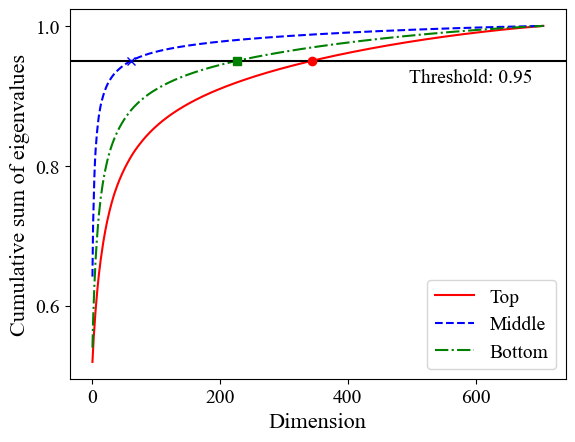

In [14]:
font = {'family' : 'Times New Roman',
        'weight' : 'normal',
        'size'   : 25}

matplotlib.rc('font', **font)

plt.plot(np.cumsum(lamy1)/np.sum(lamy1),'r-',label='Top')
plt.plot(np.cumsum(lamy2)/np.sum(lamy2),'b--',label='Middle')
plt.plot(np.cumsum(lamy3)/np.sum(lamy3),'g-.',label='Bottom')
# plt.yscale('log')
plt.axhline(y=0.95,color='black')
# Find intersections
# Function to find intersection
def find_intersection(cumsum_lamy, horizontal_value):
    idx = np.where(cumsum_lamy >= horizontal_value)[0]
    if len(idx) == 0:
        return None  # No intersection found
    idx = idx[0]
    return (idx, cumsum_lamy[idx])
intersection1 = find_intersection(np.cumsum(lamy1)/np.sum(lamy1), 0.95)
intersection2 = find_intersection(np.cumsum(lamy2)/np.sum(lamy2), 0.95)
intersection3 = find_intersection(np.cumsum(lamy3)/np.sum(lamy3), 0.95)
if intersection1:
    plt.plot(intersection1[0], intersection1[1], 'ro')
if intersection2:
    plt.plot(intersection2[0], intersection2[1], 'bx')
if intersection3:
    plt.plot(intersection3[0], intersection3[1], 'gs')

print(f'Intersection for Top: {intersection1}')
print(f'Intersection for Middle: {intersection2}')
print(f'Intersection for Bottom: {intersection3}')
plt.text(len(lamy1)*0.7, 0.92, 'Threshold: 0.95', fontsize=14, color='black')
plt.xlabel('Dimension', fontsize=16)
plt.ylabel('Cumulative sum of eigenvalues', fontsize=16)

plt.xticks(fontsize=14)
plt.yticks(fontsize=14)

plt.legend(loc='best',fontsize=14)
output_dir = "New_results"
output_path = os.path.join(output_dir, "cumulative_sum_plot.png")
# plt.savefig(output_path, dpi=600, bbox_inches='tight')
plt.show()

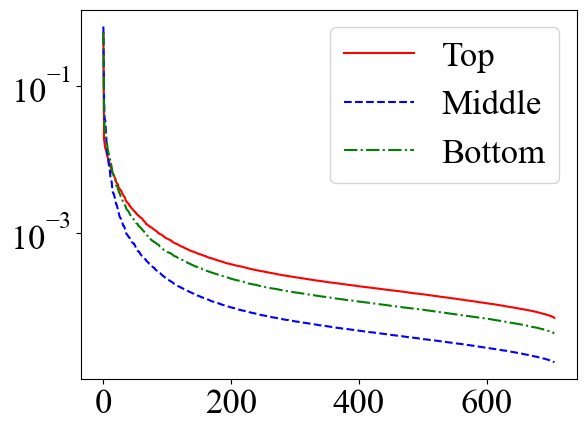

In [15]:
plt.plot((lamy1)/np.sum(lamy1),'r-',label='Top')
plt.plot((lamy2)/np.sum(lamy2),'b--',label='Middle')
plt.plot((lamy3)/np.sum(lamy3),'g-.',label='Bottom')
plt.yscale('log')
plt.legend(loc='best')

In [17]:
# Least square regression to obtain xiY and etah
# xiY is the reduced order parameter
# etah is the reduced order state variable
NY_term1 = 344
NY_term2 = 61
NY_term3 = 226
xiY1 = np.linalg.lstsq(PsiY1[:,:NY_term1],(layer1.T - meany1).T,rcond=-1)[0].T
xiY2 = np.linalg.lstsq(PsiY2[:,:NY_term2],(layer2.T - meany2).T,rcond=-1)[0].T
xiY3 = np.linalg.lstsq(PsiY3[:,:NY_term3],(layer3.T - meany3).T,rcond=-1)[0].T
# etah = np.linalg.lstsq(Psih[:,:Nh_term],(h.T - meanh).T,rcond=-1)[0].T
print(xiY1.shape)
print(xiY2.shape)
print(xiY3.shape)
# print(etah.shape)

xiY_train = xiY1[:train_size,:]
xiY_test = xiY1[train_size:,:]
# etah_train = etah[:train_size,:]
# etah_test = etah[train_size:,:]

# xiY_ref = xiY2[-1,:]
# etah_ref = etah[-1,:]
reduced_Y = np.hstack([xiY1,xiY2,xiY3])
print(reduced_Y.shape)
# np.save('New_reduced_Y_const.npy',reduced_Y)

(5001, 344)
(5001, 61)
(5001, 226)
(5001, 631)
